In [16]:
from config import *
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table
from astropy.stats import mad_std
import pandas as pd
from IPython.display import display

## Load in SFR Data

In [17]:
magphys_data = Table.read("out/sfr_magphys.fits")
halpha_data = Table.read("out/sfr_halpha.fits")

## Bin Data and Calculate Uncertainty

The standard error on the median is given by
$$ \sigma_M = 1.253 \Bigg[ \frac{\sqrt{\Sigma (x_i - \bar x)^2 / (n - 1)}}{\sqrt{n}} \Bigg] $$

In [18]:
def binned_median(rp, log_ssfr_primary, log_ssfr_controls, n_bins = N_BINS):
    """
    Bin the data and calculate the median and standard deviation in each bin.

    Parameters
    ----------
    rp : array
        The projected separation values.
    log_ssfr_primary : array
        The log of the specific star formation rate of the primary sample.
    log_ssfr_controls : array
        The log of the specific star formation rate of the control sample.
    n_bins : int
        The number of bins to use.

    Returns
    -------
    rp_med : array
        The median projected separation in each bin.
    rp_min : array
        The minimum projected separation in each bin.
    rp_max : array
        The maximum projected separation in each bin.
    ssfr_med : array
        The median specific star formation rate in each bin.
    ssfr_std : array
        The standard deviation of the specific star formation rate in each bin.
    """

    edges = np.quantile(rp, np.linspace(0, 1, n_bins + 1))
    which = np.clip(np.digitize(rp, edges[1:-1]), 0, n_bins - 1)

    ssfr_primary = 10 ** log_ssfr_primary
    ssfr_controls_med = np.median(10 ** log_ssfr_controls, axis = 1)

    out = []

    for b in range(n_bins):
        ssfr_bins, r_bins = ssfr_primary[which == b] / ssfr_controls_med[which == b], rp[which == b]
        n = len(ssfr_bins)
        sigma_bin = 1.253 * mad_std(ssfr_bins) / np.sqrt(n)
        out.append((np.median(r_bins), edges[b], edges[b + 1], np.median(ssfr_bins), sigma_bin))

    return Table(rows = out, names = ("rp_med", "rp_min", "rp_max", "ssfr_med", "ssfr_std"))

magphys_binned = binned_median(magphys_data["rp"], magphys_data["log_sSFR_primary"], magphys_data["log_sSFR_controls"])
halpha_binned = binned_median(halpha_data["rp"], halpha_data["log_sSFR_primary"], halpha_data["log_sSFR_controls"])

## Print Results

In [24]:
def print_enhancement(binned, name):
    """
    Method to display the enhancement of the specific star formation rate in each bin as a table.

    Parameters
    ----------
    binned : Table
        The binned data containing the median and standard deviation of the specific star formation rate.
    name : str
        The name of the dataset.
    """

    pct = (np.asarray(binned['ssfr_med']) - 1) * 100
    err = np.asarray(binned['ssfr_std']) * 100

    table = pd.DataFrame({
        'r<sub>p</sub> range (kpc)': [f'{lo:.1f} – {hi:.1f}' for lo, hi in zip(binned['rp_min'], binned['rp_max'])],
        'Median r<sub>p</sub> (kpc)': [f'{r:.1f}' for r in binned['rp_med']],
        'Enhancement (%)': [f'{v:+.1f} ± {e:.1f}' for v, e in zip(pct, err)]})

    display(table.style.hide(axis = 'index').set_caption(name)
            .set_table_styles([{'selector': 'caption', 'props': 'font-weight: bold; font-size: 1.1em; text-align: left;'},
            {'selector': 'th, td', 'props': 'text-align: center; padding: 4px 12px;'}]))

print_enhancement(magphys_binned, 'MagPhys (100 Myr)')
print_enhancement(halpha_binned, 'H-alpha (10 Myr)')

rp range (kpc),Median rp (kpc),Enhancement (%)
5.0 – 28.5,17.3,+30.9 ± 7.4
28.5 – 47.1,37.5,+3.1 ± 6.1
47.1 – 64.8,55.4,-12.5 ± 5.2
64.8 – 83.7,73.8,-1.2 ± 5.6
83.7 – 100.0,92.2,-10.4 ± 5.1


rp range (kpc),Median rp (kpc),Enhancement (%)
5.0 – 28.5,17.3,+54.9 ± 9.1
28.5 – 47.1,37.5,+19.0 ± 7.0
47.1 – 64.8,55.4,+4.9 ± 6.4
64.8 – 83.7,73.8,+6.9 ± 6.6
83.7 – 100.0,92.2,-10.6 ± 5.3


## Plot sSFR Enhancement Against Projected Seperation 

In [20]:
# Global plot style
plt.rcParams.update({
    'axes.linewidth': 2.0,
    'axes.labelsize': 14,
    'axes.labelweight': 'normal',
    'xtick.major.width': 2.0,
    'ytick.major.width': 2.0,
    'xtick.minor.width': 1.5,
    'ytick.minor.width': 1.5,
    'xtick.major.size': 6,
    'ytick.major.size': 6,
    'xtick.minor.size': 4,
    'ytick.minor.size': 4,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12})

# Method to bold the tick labels
def bold_ticks(*axes):
    for ax in axes:
        labels = (ax.get_xticklabels() + ax.get_yticklabels()
            + ax.get_xticklabels(minor = True) + ax.get_yticklabels(minor = True))

        for label in labels:
            label.set_fontweight('bold')

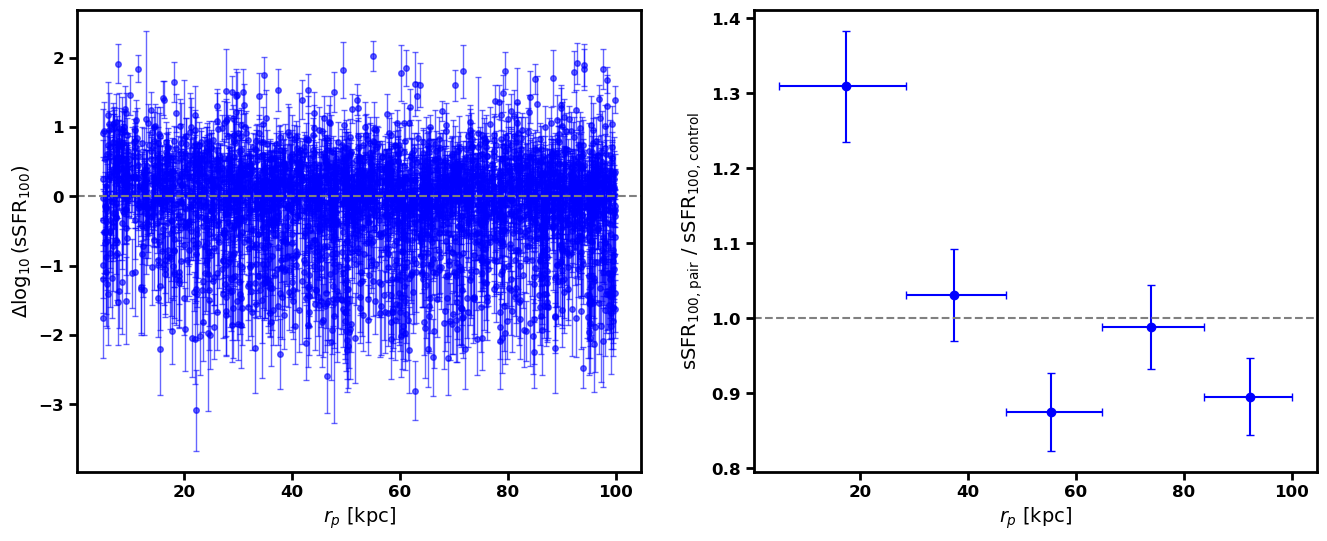

In [29]:
## Plot the MagPhys sSFR enhancement vs projected separation
fig, axes = plt.subplots(1, 2, figsize = (16, 6))

axes[0].errorbar(magphys_data['rp'], magphys_data['Delta_log_sSFR'], yerr = magphys_data['sigma_Delta_log_sSFR'], fmt = 'o', markersize = 4, color = 'blue', ecolor = 'blue', alpha = 0.6, elinewidth = 1, capsize = 2, zorder = 1)

axes[0].axhline(0, color = 'grey', ls = '--', zorder = 2)

axes[0].set_xlabel(r'$r_p$ [kpc]')
axes[0].set_ylabel(r'$\Delta\log_{10}({\rm sSFR_{100}})$')

sigma_rp = [magphys_binned["rp_med"] - magphys_binned["rp_min"], magphys_binned["rp_max"] - magphys_binned["rp_med"]]
axes[1].errorbar(magphys_binned["rp_med"], magphys_binned["ssfr_med"], yerr = magphys_binned["ssfr_std"], xerr = sigma_rp, fmt = 'o', color = 'blue', ecolor = 'blue', capsize = 3, label = "MagPhys 100 Myr", zorder = 1)

axes[1].axhline(1, color='grey', ls = '--', zorder = 2)

axes[1].set_xlabel(r'$r_p$ [kpc]')
axes[1].set_ylabel(r'sSFR$_\text{100, pair}$ / sSFR$_\text{100, control}$')

bold_ticks(*axes)

plt.savefig("figs/magphys_ssfr.pdf", format = "pdf", bbox_inches = "tight")
plt.savefig("figs/magphys_ssfr.png", format = "png", bbox_inches = "tight")

plt.show()

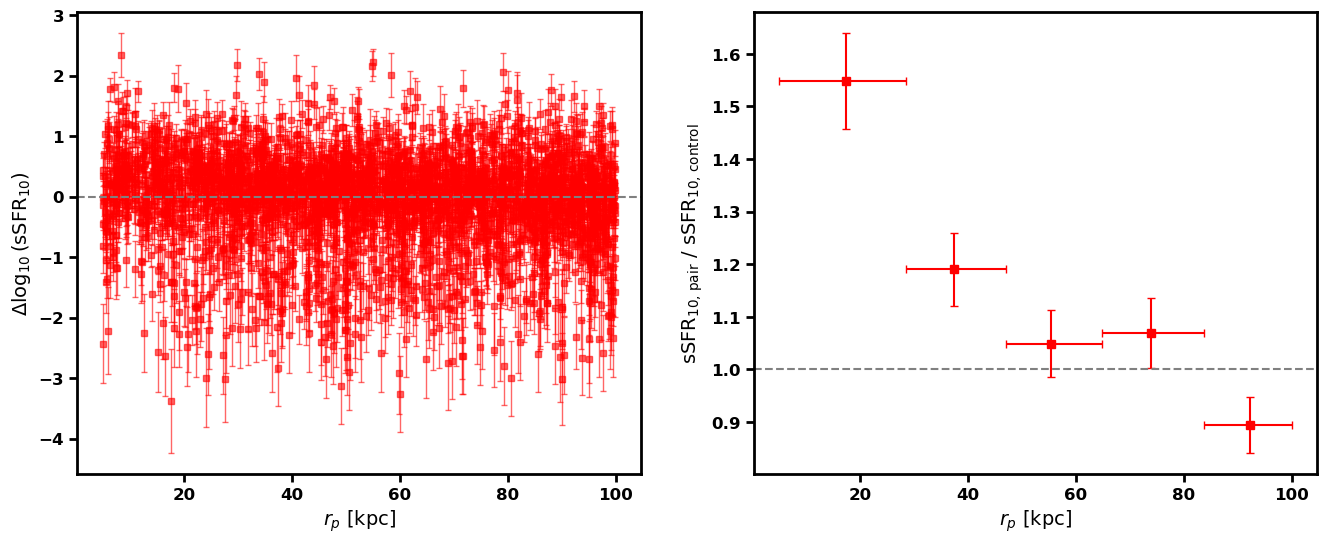

In [32]:
## Plot the H-alpha sSFR enhancement vs projected separation
fig, axes = plt.subplots(1, 2, figsize = (16, 6))

axes[0].errorbar(halpha_data['rp'], halpha_data['Delta_log_sSFR'], yerr = halpha_data['sigma_Delta_log_sSFR'], fmt = 's', markersize = 4, color = 'red', ecolor = 'red', alpha = 0.6, elinewidth = 1, capsize = 2, zorder = 1)

axes[0].axhline(0, color = 'grey', ls = '--', zorder = 2)

axes[0].set_xlabel(r'$r_p$ [kpc]')
axes[0].set_ylabel(r'$\Delta\log_{10}({\rm sSFR_{10}})$')

axes[1].set_xlabel(r'$r_p$ [kpc]')
axes[1].set_ylabel(r'sSFR$_\text{10, pair}$ / sSFR$_\text{10, control}$')

sigma_rp = [halpha_binned["rp_med"] - halpha_binned["rp_min"], halpha_binned["rp_max"] - halpha_binned["rp_med"]]
axes[1].errorbar(halpha_binned["rp_med"], halpha_binned["ssfr_med"], yerr = halpha_binned["ssfr_std"], xerr = sigma_rp, fmt = 's', color = 'red', ecolor = 'red', capsize = 3, label = "H-alpha", zorder = 1)

axes[1].axhline(1, color='grey', ls = '--', zorder = 2)

axes[1].set_xlabel(r'$r_p$ [kpc]')
axes[1].set_ylabel(r'sSFR$_\text{10, pair}$ / sSFR$_\text{10, control}$')

bold_ticks(*axes)

plt.savefig("figs/halpha_ssfr.pdf", format = "pdf", bbox_inches = "tight")
plt.savefig("figs/halpha_ssfr.png", format = "png", bbox_inches = "tight")

plt.show()